In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Период  : {df['datetime'].min()} → {df['datetime'].max()}")
print(f"Null    : {df['volume'].isnull().sum():,} ({df['volume'].isnull().mean()*100:.1f}%)")

Редове  : 52,608
Колони  : ['datetime', 'direction', 'volume', 'avg_speed']
Период  : 2022-01-01 00:00:00 → 2024-12-31 23:00:00
Null    : 16,625 (31.6%)


АНАЛИЗ НА АНОМАЛИИ В АГРЕГИРАНИЯ ВРЕМЕВИ РЕД

Център:
  Mean   : 332.0
  Median : 157.0
  Std    : 347.6
  Min    : 1.0
  Max    : 1401.0
  1%     : 3.0
  5%     : 8.0
  95%    : 974.0
  99%    : 1120.9

Околовръстно:
  Mean   : 292.8
  Median : 130.0
  Std    : 318.4
  Min    : 1.0
  Max    : 1183.0
  1%     : 1.0
  5%     : 4.0
  95%    : 874.0
  99%    : 992.0


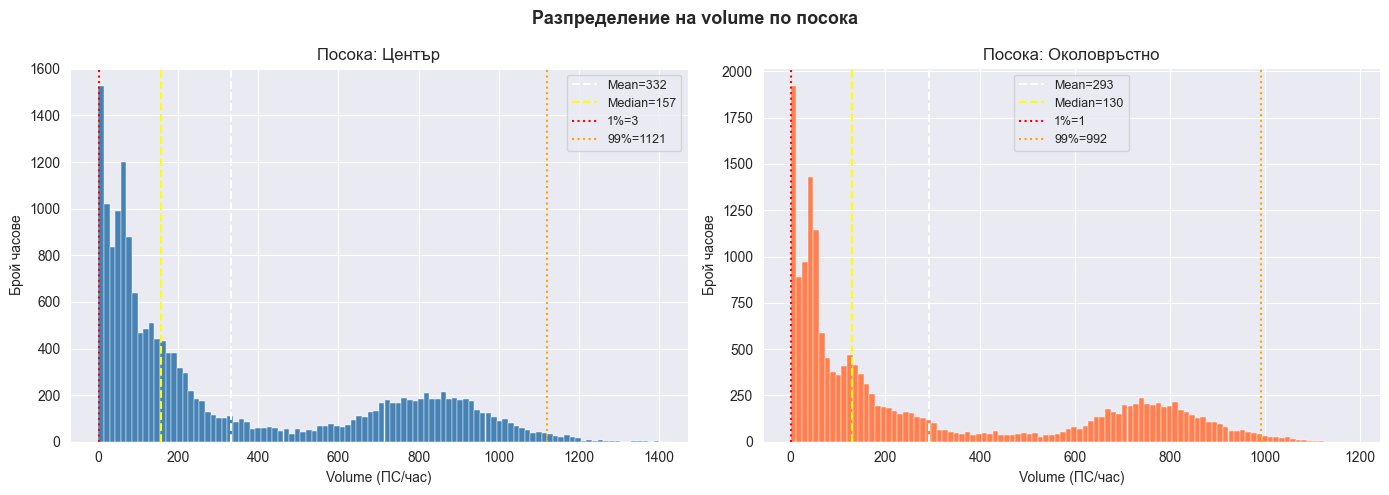

In [2]:
print("=" * 60)
print("АНАЛИЗ НА АНОМАЛИИ В АГРЕГИРАНИЯ ВРЕМЕВИ РЕД")
print("=" * 60)

for direction in ["Център", "Околовръстно"]:
    sub = df[df["direction"] == direction]["volume"].dropna()
    print(f"\n{direction}:")
    print(f"  Mean   : {sub.mean():.1f}")
    print(f"  Median : {sub.median():.1f}")
    print(f"  Std    : {sub.std():.1f}")
    print(f"  Min    : {sub.min():.1f}")
    print(f"  Max    : {sub.max():.1f}")
    print(f"  1%     : {sub.quantile(0.01):.1f}")
    print(f"  5%     : {sub.quantile(0.05):.1f}")
    print(f"  95%    : {sub.quantile(0.95):.1f}")
    print(f"  99%    : {sub.quantile(0.99):.1f}")

# Визуализация на разпределението
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Разпределение на volume по посока", fontsize=13, fontweight="bold")

for ax, direction, color in zip(axes, ["Център", "Околовръстно"],
                                 ["steelblue", "coral"]):
    sub = df[df["direction"] == direction]["volume"].dropna()
    ax.hist(sub, bins=100, color=color, edgecolor="white", linewidth=0.3)
    ax.axvline(sub.mean(),          color="white",  linestyle="--",
               label=f"Mean={sub.mean():.0f}")
    ax.axvline(sub.median(),        color="yellow", linestyle="--",
               label=f"Median={sub.median():.0f}")
    ax.axvline(sub.quantile(0.01),  color="red",    linestyle=":",
               label=f"1%={sub.quantile(0.01):.0f}")
    ax.axvline(sub.quantile(0.99),  color="orange", linestyle=":",
               label=f"99%={sub.quantile(0.99):.0f}")
    ax.set_title(f"Посока: {direction}")
    ax.set_xlabel("Volume (ПС/час)")
    ax.set_ylabel("Брой часове")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("volume_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
print("=" * 60)
print("АНАЛИЗ НА НИСКИТЕ СТОЙНОСТИ")
print("=" * 60)

# Часове с много малко записи
for direction in ["Център", "Околовръстно"]:
    sub = df[df["direction"] == direction].copy()
    
    low = sub[sub["volume"] < 10].copy()
    print(f"\n{direction} — часове с volume < 10:")
    print(f"  Брой    : {len(low):,}")
    print(f"  По час  :")
    print(low["datetime"].dt.hour.value_counts().sort_index().to_string())
    print(f"\n  По година:")
    print(low["datetime"].dt.year.value_counts().sort_index().to_string())
    print(f"\n  По месец:")
    print(low["datetime"].dt.month.value_counts().sort_index().to_string())

АНАЛИЗ НА НИСКИТЕ СТОЙНОСТИ

Център — часове с volume < 10:
  Брой    : 1,028
  По час  :
datetime
0      69
1     180
2     220
3     209
4     161
5      61
6      18
7      12
8       7
9       3
10      1
11      8
12      1
13      6
14      3
15      5
16      4
17      8
18      4
19      5
20      9
21      8
22      6
23     20

  По година:
datetime
2022    232
2023    258
2024    538

  По месец:
datetime
1      56
2      67
3      87
4      99
5     145
6     119
7     217
8     108
9     116
10     14

Околовръстно — часове с volume < 10:
  Брой    : 1,625
  По час  :
datetime
0     143
1     268
2     274
3     254
4     279
5     189
6      49
7      10
8       9
9       3
10      3
11      2
12      4
13      6
14      6
15      7
16     10
17      6
18     11
19      8
20     13
21     16
22     18
23     37

  По година:
datetime
2022    417
2023    484
2024    724

  По месец:
datetime
1      15
2      65
3     158
4     197
5     244
6     169
7     369
8     146
9 

ВИЗУАЛИЗАЦИЯ НА АНОМАЛНИТЕ ДНЕВНИ СТОЙНОСТИ


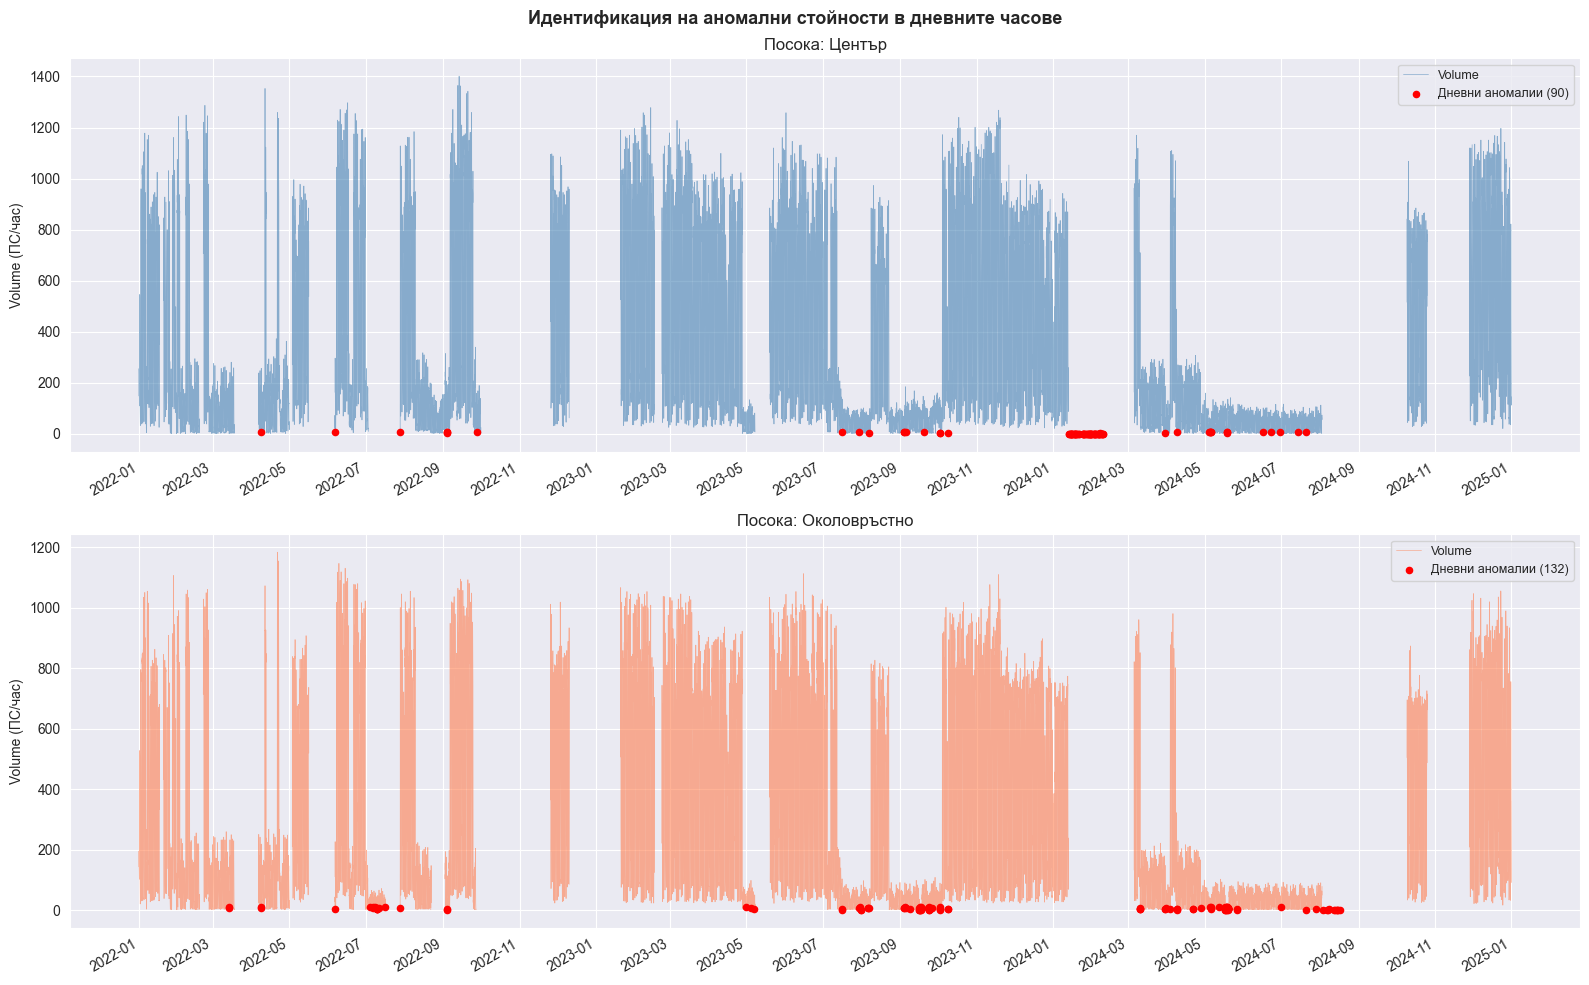


Център — дневни аномалии (7-22h, volume<10):
  Брой     : 90
  По година: 
datetime
2022     7
2023    10
2024    73

Околовръстно — дневни аномалии (7-22h, volume<10):
  Брой     : 132
  По година: 
datetime
2022    19
2023    50
2024    63


In [4]:
print("=" * 60)
print("ВИЗУАЛИЗАЦИЯ НА АНОМАЛНИТЕ ДНЕВНИ СТОЙНОСТИ")
print("=" * 60)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Идентификация на аномални стойности в дневните часове",
             fontsize=13, fontweight="bold")

for ax, direction, color in zip(axes, ["Център", "Околовръстно"],
                                 ["steelblue", "coral"]):
    sub = df[df["direction"] == direction].copy()
    
    # Аномални = дневни часове (7-22h) с volume < 10
    daytime_low = sub[
        (sub["datetime"].dt.hour.between(7, 22)) &
        (sub["volume"] < 10)
    ]
    
    ax.plot(sub["datetime"], sub["volume"],
            color=color, linewidth=0.5, alpha=0.6, label="Volume")
    ax.scatter(daytime_low["datetime"], daytime_low["volume"],
               color="red", s=20, zorder=5, 
               label=f"Дневни аномалии ({len(daytime_low):,})")
    
    ax.set_title(f"Посока: {direction}")
    ax.set_ylabel("Volume (ПС/час)")
    ax.legend(fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("anomaly_detection.png", dpi=150, bbox_inches="tight")
plt.show()

# Колко са дневните аномалии?
for direction in ["Център", "Околовръстно"]:
    sub = df[df["direction"] == direction].copy()
    daytime_low = sub[
        (sub["datetime"].dt.hour.between(7, 22)) &
        (sub["volume"] < 10)
    ]
    print(f"\n{direction} — дневни аномалии (7-22h, volume<10):")
    print(f"  Брой     : {len(daytime_low):,}")
    print(f"  По година: ")
    print(daytime_low["datetime"].dt.year.value_counts().sort_index().to_string())

АНАЛИЗ НА ДНЕВНИ СТОЙНОСТИ ПОД 400 ПС/ЧАС

Център — дневни часове (7-22h):
  Общо дневни часове    : 12,042
  Под 400 ПС/час        : 6,270 (52.1%)
  По час (под 400):
datetime
7     471
8     437
9     394
10    337
11    336
12    331
13    331
14    329
15    335
16    332
17    331
18    332
19    336
20    345
21    552
22    741

Околовръстно — дневни часове (7-22h):
  Общо дневни часове    : 11,946
  Под 400 ПС/час        : 6,549 (54.8%)
  По час (под 400):
datetime
7     469
8     424
9     349
10    327
11    327
12    329
13    325
14    327
15    332
16    330
17    325
18    333
19    340
20    530
21    737
22    745


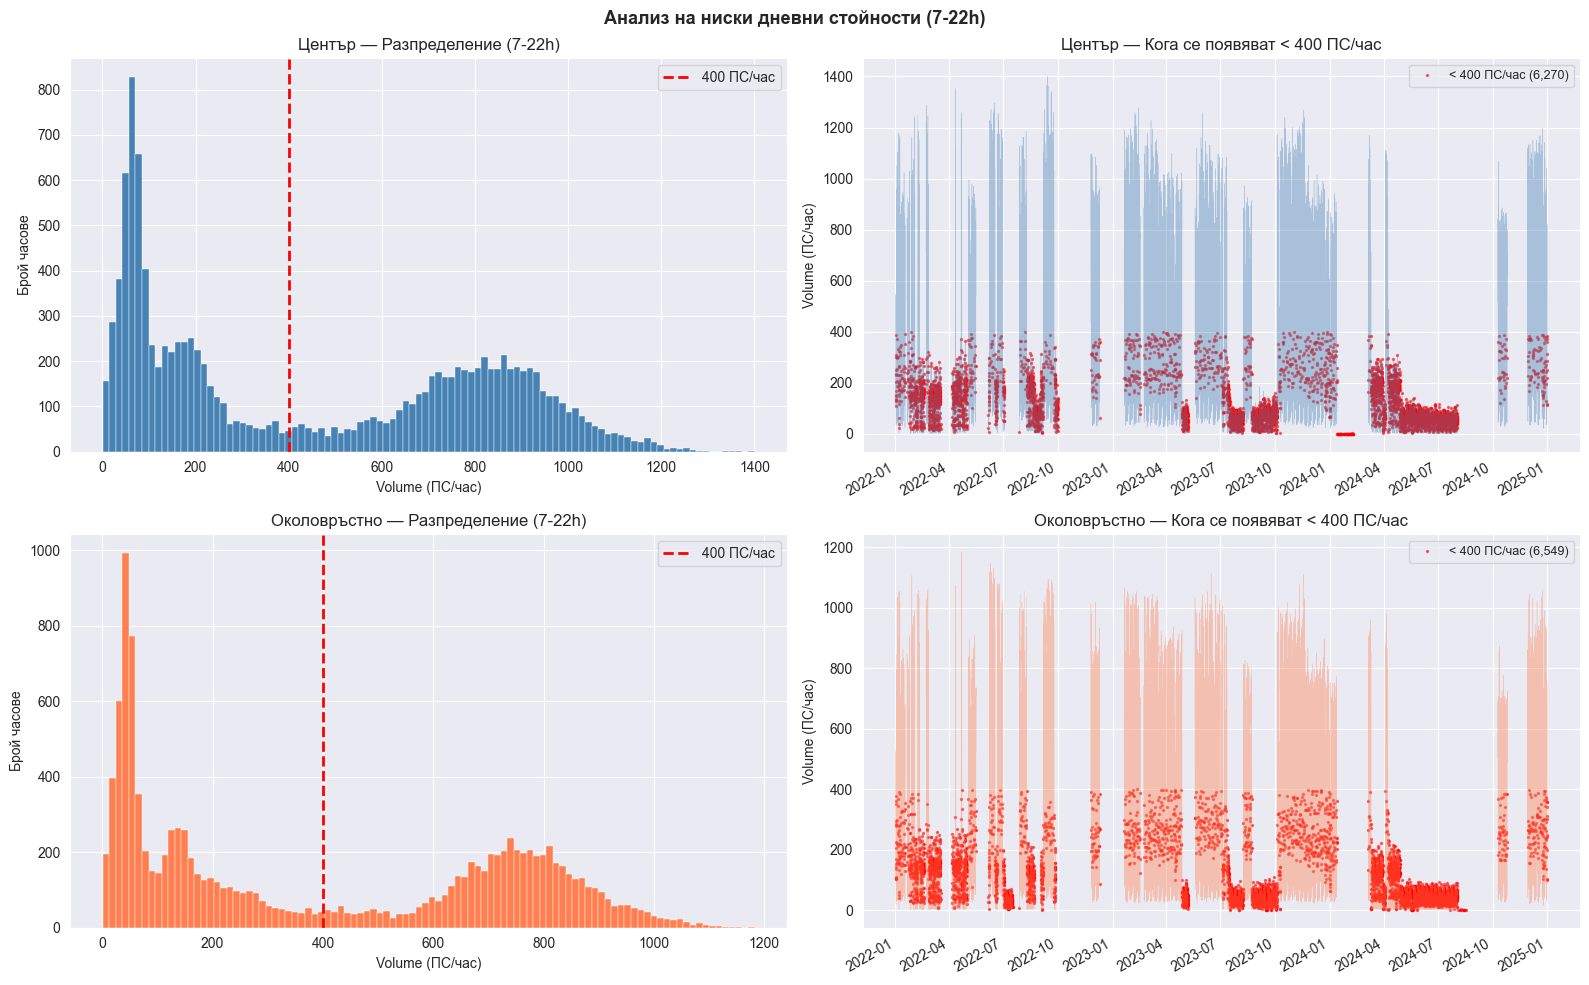

In [5]:
print("=" * 60)
print("АНАЛИЗ НА ДНЕВНИ СТОЙНОСТИ ПОД 400 ПС/ЧАС")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Анализ на ниски дневни стойности (7-22h)", 
             fontsize=13, fontweight="bold")

for i, direction in enumerate(["Център", "Околовръстно"]):
    sub = df[df["direction"] == direction].copy()
    daytime = sub[sub["datetime"].dt.hour.between(7, 22)]
    
    # Разпределение на дневните стойности
    axes[i, 0].hist(daytime["volume"].dropna(), bins=100, 
                    color=["steelblue","coral"][i], 
                    edgecolor="white", linewidth=0.3)
    axes[i, 0].axvline(x=400, color="red", linestyle="--", 
                       linewidth=2, label="400 ПС/час")
    axes[i, 0].set_title(f"{direction} — Разпределение (7-22h)")
    axes[i, 0].set_xlabel("Volume (ПС/час)")
    axes[i, 0].set_ylabel("Брой часове")
    axes[i, 0].legend()
    
    # Колко са под 400 в дневните часове?
    low_day = daytime[daytime["volume"] < 400]
    pct     = len(low_day) / len(daytime.dropna()) * 100
    
    print(f"\n{direction} — дневни часове (7-22h):")
    print(f"  Общо дневни часове    : {len(daytime.dropna()):,}")
    print(f"  Под 400 ПС/час        : {len(low_day):,} ({pct:.1f}%)")
    print(f"  По час (под 400):")
    print(low_day["datetime"].dt.hour.value_counts().sort_index().to_string())
    
    # Кога се появяват — по дата
    axes[i, 1].scatter(low_day["datetime"], low_day["volume"],
                       s=2, alpha=0.5, color="red",
                       label=f"< 400 ПС/час ({len(low_day):,})")
    axes[i, 1].plot(sub["datetime"], sub["volume"],
                    color=["steelblue","coral"][i], 
                    linewidth=0.3, alpha=0.4)
    axes[i, 1].set_title(f"{direction} — Кога се появяват < 400 ПС/час")
    axes[i, 1].set_ylabel("Volume (ПС/час)")
    axes[i, 1].legend(fontsize=9)
    axes[i, 1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    axes[i, 1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.setp(axes[i, 1].xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("low_daytime_values.png", dpi=150, bbox_inches="tight")
plt.show()